## Dante Solorzano Ferrer
## TSP (traveler salesman problem)
## Inteligencia Artificial 
## Profesor: Andres Espinal Jimenez

# Celda 1: Importación de librerías y parseo de datos

In [1]:
import numpy as np
import math
import random
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Función para leer el archivo berlin52.tsp
def cargar_berlin52(ruta_archivo='berlin52.tsp'):
    coordenadas = []
    leyendo_nodos = False
    try:
        with open(ruta_archivo, 'r') as f:
            for linea in f:
                if linea.startswith('EOF'):
                    break
                if leyendo_nodos:
                    partes = linea.strip().split()
                    if len(partes) >= 3:
                        coordenadas.append((float(partes[1]), float(partes[2])))
                if linea.startswith('NODE_COORD_SECTION'):
                    leyendo_nodos = True
        return np.array(coordenadas)
    except FileNotFoundError:
        print(f"Error: No se encontró el archivo {ruta_archivo}.")
        return None

ciudades = cargar_berlin52()

# Matriz de distancias euclídeas redondeadas
N_CIUDADES = 52
distancias = np.zeros((N_CIUDADES, N_CIUDADES))
if ciudades is not None:
    for i in range(N_CIUDADES):
        for j in range(N_CIUDADES):
            if i != j:
                dx = ciudades[i][0] - ciudades[j][0]
                dy = ciudades[i][1] - ciudades[j][1]
                distancias[i][j] = int(round(math.sqrt(dx**2 + dy**2)))

def funcion_objetivo(cromosoma):
    costo = 0
    for i in range(N_CIUDADES - 1):
        costo += distancias[cromosoma[i]][cromosoma[i+1]]
    costo += distancias[cromosoma[-1]][cromosoma[0]]
    return costo

# Celda 2: Decodificación Gray y Reparador Cromosómico

In [2]:
def reparar_cromosoma(cromosoma_entero):
    """Reparador genérico para asegurar permutación válida"""
    conteo = np.bincount(cromosoma_entero, minlength=N_CIUDADES)
    faltantes = np.where(conteo == 0)[0].tolist()
    
    vistos = set()
    indices_a_reemplazar = []
    
    for i, gen in enumerate(cromosoma_entero):
        if gen in vistos or gen >= N_CIUDADES:
            indices_a_reemplazar.append(i)
        else:
            vistos.add(gen)
            
    random.shuffle(faltantes)
    cromosoma_reparado = list(cromosoma_entero)
    
    for idx, faltante in zip(indices_a_reemplazar, faltantes):
        cromosoma_reparado[idx] = faltante
        
    return cromosoma_reparado

def gray_a_binario(gray_bits):
    bin_bits = np.zeros(len(gray_bits), dtype=int)
    bin_bits[0] = gray_bits[0]
    for i in range(1, len(gray_bits)):
        bin_bits[i] = bin_bits[i-1] ^ gray_bits[i]
    return bin_bits

def decodificar_gray(cromosoma_gray):
    ciudades_decodificadas = []
    for i in range(N_CIUDADES):
        bloque = cromosoma_gray[i*6 : (i+1)*6]
        binario = gray_a_binario(bloque)
        # Convertir binario a entero
        valor_entero = int("".join(str(x) for x in binario), 2)
        ciudades_decodificadas.append(valor_entero % N_CIUDADES)
        
    return reparar_cromosoma(ciudades_decodificadas)

# Celda 3: Operadores Genéticos (Selección, Cruza, Mutación)

In [3]:
def seleccion_ranking(poblacion, fitness):
    # Ordenar índices de peor a mejor (maximizar ranking)
    indices_ordenados = np.argsort(fitness)[::-1] 
    probabilidades = np.arange(1, len(poblacion) + 1)
    probabilidades = probabilidades / np.sum(probabilidades)
    
    padre1_idx = np.random.choice(indices_ordenados, p=probabilidades)
    padre2_idx = np.random.choice(indices_ordenados, p=probabilidades)
    return poblacion[padre1_idx], poblacion[padre2_idx]

# Operadores para Binario (Gray)
def cruza_dos_puntos_binario(p1, p2):
    pt1, pt2 = sorted(random.sample(range(len(p1)), 2))
    hijo1 = np.concatenate((p1[:pt1], p2[pt1:pt2], p1[pt2:]))
    hijo2 = np.concatenate((p2[:pt1], p1[pt1:pt2], p2[pt2:]))
    return hijo1, hijo2

def mutacion_k_bits(cromosoma, k=4):
    indices = random.sample(range(len(cromosoma)), k)
    hijo = cromosoma.copy()
    for idx in indices:
        hijo[idx] = 1 - hijo[idx] # Negación
    return hijo

# Operadores para Entero
def cruza_orden_ox(p1, p2):
    pt1, pt2 = sorted(random.sample(range(N_CIUDADES), 2))
    hijo1, hijo2 = [-1]*N_CIUDADES, [-1]*N_CIUDADES
    
    hijo1[pt1:pt2] = p1[pt1:pt2]
    hijo2[pt1:pt2] = p2[pt1:pt2]
    
    def rellenar_ox(hijo, padre_opuesto):
        puntero = pt2
        for ciudad in padre_opuesto[pt2:] + padre_opuesto[:pt2]:
            if ciudad not in hijo:
                if puntero == N_CIUDADES: puntero = 0
                hijo[puntero] = ciudad
                puntero += 1
        return hijo
        
    return rellenar_ox(hijo1, p2), rellenar_ox(hijo2, p1)

def mutacion_swap(cromosoma):
    hijo = cromosoma.copy()
    idx1, idx2 = random.sample(range(N_CIUDADES), 2)
    hijo[idx1], hijo[idx2] = hijo[idx2], hijo[idx1]
    return reparar_cromosoma(hijo) # Seguro por si acaso

# Celda 4: Algoritmo Genético Principal

In [10]:
def ejecutar_ag(representacion, pob_size=100, epocas=1000):
    poblacion = []
    
    # Inicialización
    for _ in range(pob_size):
        if representacion == 'entera':
            poblacion.append(random.sample(range(N_CIUDADES), N_CIUDADES))
        else: # binaria
            poblacion.append(np.random.randint(2, size=N_CIUDADES*6))
            
    historial_mejor_fitness = []
    mejor_historico = float('inf')
    
    for epoca in range(epocas):
        # Evaluación
        fitness = []
        for ind in poblacion:
            if representacion == 'binaria':
                ruta = decodificar_gray(ind)
            else:
                ruta = ind
            fitness.append(funcion_objetivo(ruta))
            
        mejor_epoca = min(fitness)
        mejor_historico = min(mejor_historico, mejor_epoca)
        historial_mejor_fitness.append(mejor_historico)
        
        # Elitismo: Guardar el mejor
        mejor_idx = np.argmin(fitness)
        nueva_poblacion = [poblacion[mejor_idx]]
        
        # Generar nueva población
        while len(nueva_poblacion) < pob_size:
            p1, p2 = seleccion_ranking(poblacion, fitness)
            
            if representacion == 'entera':
                h1, h2 = cruza_orden_ox(p1, p2)
                if random.random() < 0.1: h1 = mutacion_swap(h1)
                if random.random() < 0.1: h2 = mutacion_swap(h2)
            else:
                h1, h2 = cruza_dos_puntos_binario(p1, p2)
                h1 = mutacion_k_bits(h1, k=4)
                h2 = mutacion_k_bits(h2, k=4)
                
            nueva_poblacion.extend([h1, h2])
            
        poblacion = nueva_poblacion[:pob_size]
        
    return historial_mejor_fitness

# Celda 5: Configuración Experimental (35 Corridas) y Análisis Estadístico

In [11]:
# ADVERTENCIA: Esta celda puede tardar un par de minutos en ejecutarse
N_CORRIDAS = 35
EPOCAS = 1000

resultados_enteros = []
resultados_binarios = []

print("Ejecutando 35 corridas para Representación Entera...")
for _ in range(N_CORRIDAS):
    resultados_enteros.append(ejecutar_ag('entera', epocas=EPOCAS))

print("Ejecutando 35 corridas para Representación Binaria (Gray)...")
for _ in range(N_CORRIDAS):
    resultados_binarios.append(ejecutar_ag('binaria', epocas=EPOCAS))

resultados_enteros = np.array(resultados_enteros)
resultados_binarios = np.array(resultados_binarios)

# Extraer el mejor valor final de cada corrida
mejores_enteros = resultados_enteros[:, -1]
mejores_binarios = resultados_binarios[:, -1]

print("\n--- Análisis Estadístico (Mejores Valores Finales) ---")
print(f"Representación Entera - Media: {np.mean(mejores_enteros):.2f}, Mediana: {np.median(mejores_enteros):.2f}, Desv. Est: {np.std(mejores_enteros):.2f}")
print(f"Representación Binaria - Media: {np.mean(mejores_binarios):.2f}, Mediana: {np.median(mejores_binarios):.2f}, Desv. Est: {np.std(mejores_binarios):.2f}")

Ejecutando 35 corridas para Representación Entera...
Ejecutando 35 corridas para Representación Binaria (Gray)...

--- Análisis Estadístico (Mejores Valores Finales) ---
Representación Entera - Media: 11321.20, Mediana: 11443.00, Desv. Est: 625.05
Representación Binaria - Media: 17000.91, Mediana: 17165.00, Desv. Est: 583.62


# Celda 6: Visualizaciones Obligatorias

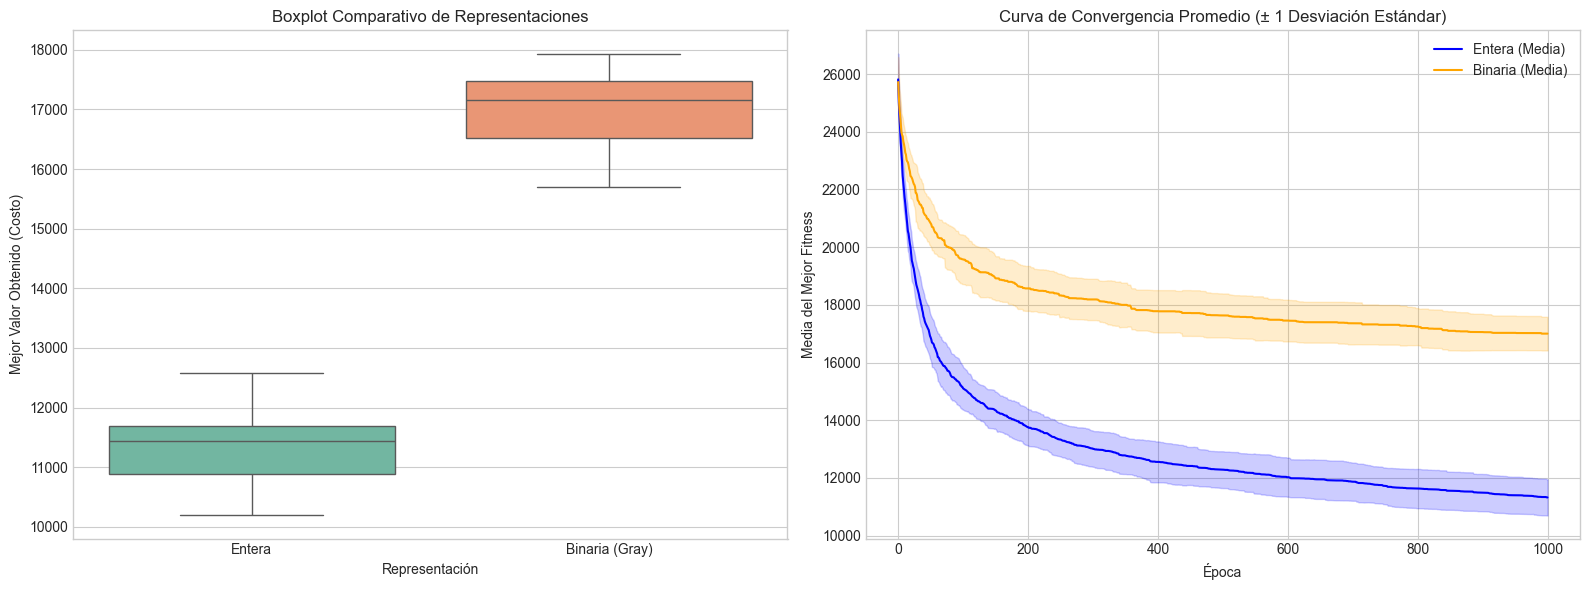

In [12]:
plt.style.use('seaborn-v0_8-whitegrid')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# 1) Boxplot Comparativo
sns.boxplot(data=[mejores_enteros, mejores_binarios], ax=ax1, palette="Set2")
ax1.set_xticklabels(['Entera', 'Binaria (Gray)'])
ax1.set_title('Boxplot Comparativo de Representaciones')
ax1.set_xlabel('Representación')
ax1.set_ylabel('Mejor Valor Obtenido (Costo)')

# 2) Curva de Convergencia Promedio
# Representación Entera
medias_ent = np.mean(resultados_enteros, axis=0)
std_ent = np.std(resultados_enteros, axis=0)
epocas_x = np.arange(EPOCAS)

ax2.plot(epocas_x, medias_ent, label='Entera (Media)', color='blue')
ax2.fill_between(epocas_x, medias_ent - std_ent, medias_ent + std_ent, color='blue', alpha=0.2)

# Representación Binaria
medias_bin = np.mean(resultados_binarios, axis=0)
std_bin = np.std(resultados_binarios, axis=0)

ax2.plot(epocas_x, medias_bin, label='Binaria (Media)', color='orange')
ax2.fill_between(epocas_x, medias_bin - std_bin, medias_bin + std_bin, color='orange', alpha=0.2)

ax2.set_title('Curva de Convergencia Promedio (± 1 Desviación Estándar)')
ax2.set_xlabel('Época')
ax2.set_ylabel('Media del Mejor Fitness')
ax2.legend()

plt.tight_layout()
plt.show()